In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv('../data/04_data_analysis/00_all_data.csv')
df.head()

,Unnamed: 0,subject,condition,position_index,billboard_image_at_position,billboard_attention_level,billboard#_fixated,billboard#_fixated_count,billboard#_duration,recall,recognition
0,0,sub001,Free_Viewing,1,ad_movingbusiness,more_attention,0,0,0.00,0,0.0
1,1,sub001,Free_Viewing,2,ad_lawyer,less_attention,1,1,0.61,0,NaN
2,2,sub001,Free_Viewing,3,ad_furniture,more_attention,0,0,0.00,0,0.0
3,3,sub001,Free_Viewing,4,ad_burger,less_attention,0,0,0.00,0,0.0
4,4,sub001,Free_Viewing,5,health_drugabuse,more_attention,1,2,1.97,0,0.0


In [3]:
result = pd.crosstab(df['position_index'], df['billboard_image_at_position'], values=df['billboard#_fixated'], 
                        aggfunc=  lambda x: x.sum(min_count=0) )
result.to_csv('../data/04_data_analysis/ads_by_position.csv')


result_grouped = df.groupby('position_index')[['billboard#_fixated_count', 'recognition']].sum().reset_index()
result_grouped.rename(columns={'position_index': 'Position'}, inplace=True)
result_grouped.head()

,Position,billboard#_fixated_count,recognition
0,1,24,9.0
1,2,14,8.0
2,3,39,10.0
3,4,18,11.0
4,5,92,18.0


In [4]:
df_pos = pd.read_csv('../data/04_data_analysis/01_position_index.csv')[['Position', 'Horizontal','Vertical']]
df_pos.head()

,Position,Horizontal,Vertical
0,1,-27.5,54.6
1,2,11.7,114.7
2,3,-57.9,146.2
3,4,21.2,153.2
4,5,-32.0,201.3


In [5]:

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Fit and transform the data
df_pos['Horizontal'] = scaler.fit_transform(df_pos[['Horizontal']])
df_pos['Vertical'] = scaler.fit_transform(df_pos[['Vertical']])

df_pos.head()

/Users/suelim/anaconda3/lib/python3.10/site-packages/sklearn/utils/validation.py:767: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if not hasattr(array, "sparse") and array.dtypes.apply(is_sparse).any():
/Users/suelim/anaconda3/lib/python3.10/site-packages/sklearn/utils/validation.py:605: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if is_sparse(pd_dtype):
/Users/suelim/anaconda3/lib/python3.10/site-packages/sklearn/utils/validation.py:614: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if is_sparse(pd_dtype) or not is_extension_array_dtype(pd_dtype):
/Users/suelim/anaconda3/lib/python3.10/site-packages/sklearn/utils/validation.py:767: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinsta

,Position,Horizontal,Vertical
0,1,0.370280,0.000000
1,2,0.847747,0.045019
2,3,0.000000,0.068614
3,4,0.963459,0.073858
4,5,0.315469,0.109888


(-0.05, 1.05, -0.05, 1.05)

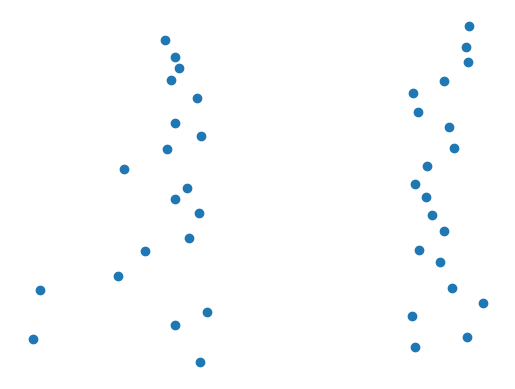

In [6]:
plt.scatter(df_pos['Horizontal'], df_pos['Vertical']); 
plt.axis('off')

In [7]:
df_merged = df_pos.merge(result_grouped, on='Position')
df_merged.head()

,Position,Horizontal,Vertical,billboard#_fixated_count,recognition
0,1,0.370280,0.000000,24,9.0
1,2,0.847747,0.045019,14,8.0
2,3,0.000000,0.068614,39,10.0
3,4,0.963459,0.073858,18,11.0
4,5,0.315469,0.109888,92,18.0


In [9]:
from scipy.stats import pearsonr

pearsonr(df_merged["billboard#_fixated_count"], df_merged["recognition"])

PearsonRResult(statistic=0.4839871991091425, pvalue=0.0015550050175682489)

/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


(-0.05, 1.05, -0.05, 1.05)

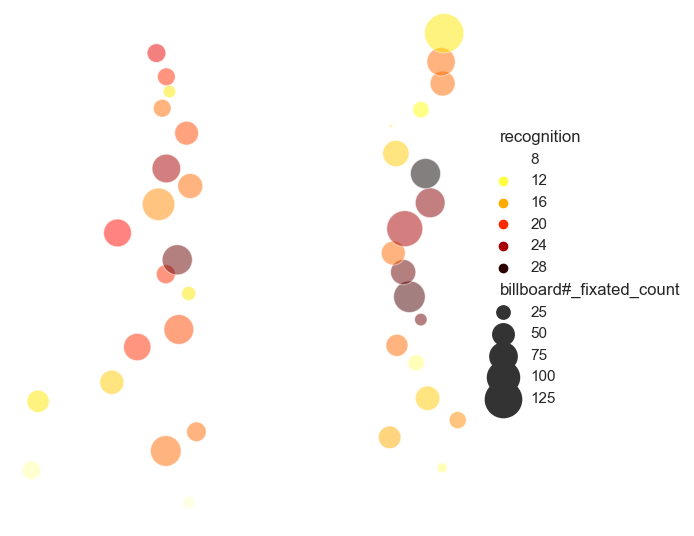

In [82]:
import seaborn as sns
sns.set_theme(style="white")

sns.relplot(x="Horizontal", y="Vertical", size="billboard#_fixated_count",
            sizes=(4, 800), alpha=.5, hue = 'recognition', palette="hot_r",
            height=6, aspect = 0.96, data=df_merged);
plt.axis('off')

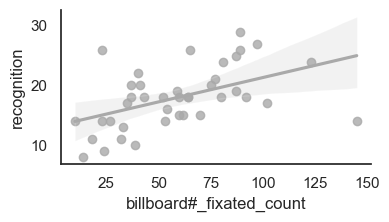

In [108]:
fig, ax = plt.subplots(figsize=(4, 2))
sns.set_context("notebook")

sns.regplot(x="billboard#_fixated_count", y="recognition",  #kind="reg", 
              data=df_merged, color = 'darkgray')# height = 3);
sns.despine();
